# Assignment 2 — Fine-tuning YOLOv3 on a New Dataset

**CSCI 4052U — Machine Learning II** · **Unit.** `fast_object_detection_networks`
· **Weight.** 100 marks

In Lab 3 you ran a pretrained YOLOv3-tiny over COCO images and measured where it
failed. It had been trained on COCO's 80 classes and you took it as it came.

This assignment asks the next question: **what happens when the classes you care about
are not COCO's?** You will fine-tune the same detector on the African Wildlife dataset
— `buffalo`, `elephant`, `rhino`, `zebra` — and measure what the fine-tuning bought.

Two of those four classes are already in COCO and two are not, which is the thing to
keep an eye on throughout.

## What to hand in

1. **This notebook, with every cell run and its output visible.** Do not clear the
   outputs — the figures and tables *are* the answer.
2. **Your written answers**, typed into the markdown cells marked **Your answer**.
   Each asks for two or three sentences. No separate report file.

| Part | | Marks |
|---|---|---|
| 1 | What the pretrained detector already knows | 20 |
| 2 | Fine-tune it | 30 |
| 3 | Measure what changed | 30 |
| 4 | One experiment of your own | 20 |

## Before you start

**Use a GPU runtime.** On Colab: *Runtime → Change runtime type → T4 GPU*. The
training in Part 2 takes a few minutes on a GPU and far too long without one.

**Colab is ephemeral.** *File → Save a copy in Drive* before you do any work, or you
will lose it.

---

## A five-minute introduction to Ultralytics

Everything in this assignment goes through one library, and almost all of it through one
class. Read this once and the rest of the notebook will look obvious.

### One object, three verbs

```python
from ultralytics import YOLO

model = YOLO("yolov3-tinyu.pt")   # load a checkpoint (downloads it the first time)
model.predict(...)                #  run it on images
model.train(...)                  #  train it on a dataset
model.val(...)                    #  score it against ground truth
```

A `YOLO` object is the network *and* its training loop *and* its evaluator. There is no
separate `Trainer` to assemble, no `DataLoader` to write, no optimiser to choose — which
is why this assignment is short.

### What `predict` gives back

A **list of `Results`, one per image**, in the order you passed them. Each carries a
`.boxes` with three parallel tensors:

```python
r = model.predict("zebra.jpg", conf=0.25)[0]
r.boxes.cls      # tensor of class indices,  one per detected box
r.boxes.xyxy     # tensor of (x1, y1, x2, y2) corners, in pixels
r.boxes.conf     # tensor of confidence scores
r.plot()         # the image with the boxes drawn on it, as a numpy array (BGR)
```

`model.names` turns a class index into a name — `model.names[22]` is `'zebra'`. **Which
names you get depends on the checkpoint**: a COCO model knows 80, and the model you
fine-tune in Part 2 will know four. Keeping those two vocabularies straight is most of
Part 1.

`.plot()` returns **BGR** (an OpenCV habit) while matplotlib expects RGB, which is why
the provided helper writes `r.plot()[..., ::-1]` — that reverses the last axis.

### How a dataset is described

Not by code. A dataset is a small YAML file naming the image folders and the classes:

```yaml
path: ../datasets/african-wildlife
train: images/train
val: images/val
test: images/test
names:
  0: buffalo
  1: elephant
  2: rhino
  3: zebra
```

Pass `data="african-wildlife.yaml"` and Ultralytics finds that file among the ones it
ships, downloads the dataset if it is missing, and reads the labels beside the images:
one `.txt` per image, one line per object, `class cx cy w h` with the four box numbers
normalised to [0, 1].

### Where the output goes

Every `train` and `val` call writes a folder under `project/name`:

```
runs/finetune/
    results.csv          one row per epoch -- the numbers you plot in 2.2
    weights/best.pt      the checkpoint that scored best on the validation split
    weights/last.pt      the checkpoint from the final epoch
```

`train` returns an object whose `.save_dir` is that path. **Reusing a `name=` with
`exist_ok=True` overwrites the folder**, which is the trap Part 4 warns you about.

### What `val` gives back

A metrics object. The three numbers this assignment wants:

```python
m = model.val(data=DATA, split="test")
m.box.map50      # mAP at IoU 0.50, a single float
m.box.map        # mAP averaged over IoU 0.50:0.05:0.95
m.box.ap50       # per-class mAP50, an array ordered like m.names
```

### The one thing to watch

Ultralytics is **opinionated**. It picks the optimiser, the learning-rate schedule and a
stack of augmentations for you, and it prints a large block of settings at the start of
every run. You are not expected to tune any of that. The arguments this assignment names
— `epochs`, `imgsz`, `batch`, `freeze`, `seed` — are the only ones you should change.

---

## Setup

Provided — run it and move on. Installs `ultralytics`, downloads the African Wildlife
dataset (about 100 MB, done once) and checks that a GPU is visible.

In [ ]:
import subprocess, sys
try:
    import ultralytics  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.3.228"],
                   check=True)

In [ ]:
import os

# Ultralytics prints a banner on every call unless told otherwise.
os.environ["YOLO_VERBOSE"] = "false"

from pathlib import Path

import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO
from ultralytics.data.utils import check_det_dataset

# Ultralytics wants 0 (the first GPU) or the string "cpu", not a torch.device.
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (expect this to be slow)")

# Naming the YAML is enough: this downloads the dataset if it is missing and
# returns a dict describing it.
DATA = "african-wildlife.yaml"
info = check_det_dataset(DATA)

CLASSES = info["names"]       # {0: 'buffalo', 1: 'elephant', 2: 'rhino', 3: 'zebra'}
TEST_DIR = Path(info["test"])  # the images/test folder, wherever it was unpacked
TEST_IMAGES = sorted(TEST_DIR.glob("*.jpg"))  # sorted, so everyone sees the same order

print("classes:", CLASSES)
print(f"{len(TEST_IMAGES)} test images at {TEST_DIR}")


def ground_truth_classes(image_path):
    """The set of class indices annotated in one image.

    The labels live in a folder beside the images with the same layout, so the
    path to an image's annotation is the image's path with 'images' swapped for
    'labels' and the extension changed. Each line is 'class cx cy w h'; the
    class is the first field, which is all this helper needs.
    """
    label = Path(str(image_path).replace("/images/", "/labels/")).with_suffix(".txt")
    if not label.exists():
        return set()          # an image with no annotation file holds no objects
    return {int(line.split()[0]) for line in label.read_text().splitlines() if line.strip()}


def show(results, titles=None, cols=4, size=3.4):
    """Draw a list of ultralytics Results in a grid.

    Pass it whatever model.predict(...) returned, plus one title per panel.
    r.plot() renders the image with its boxes already drawn, so nothing here
    has to know about coordinates.
    """
    n = len(results)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), dpi=80)
    for ax, r, t in zip(getattr(axes, "flat", [axes]), results,
                        titles or [None] * n):
        # .plot() hands back BGR; [..., ::-1] flips it to the RGB matplotlib wants
        ax.imshow(r.plot()[..., ::-1])
        ax.set_xticks([]); ax.set_yticks([])
        if t:
            ax.set_title(t, fontsize=10)
    for ax in list(getattr(axes, "flat", [axes]))[n:]:
        ax.axis("off")
    fig.tight_layout()
    plt.show()
    return fig

device: Tesla T4
classes: {0: 'buffalo', 1: 'elephant', 2: 'rhino', 3: 'zebra'}
227 test images at /content/datasets/african-wildlife/images/test


---

# Part 1 — What the pretrained detector already knows (20 marks)

The COCO-pretrained YOLOv3-tiny has never seen this dataset. But COCO does contain
`elephant` and `zebra`, and does **not** contain `buffalo` or `rhino`.

### 1.1 Look at it (8 marks) — **Your turn**

Load `yolov3-tinyu.pt`, run it on the first 8 test images, and display the results
with `show(...)`.

```python
model = YOLO("yolov3-tinyu.pt")
results = model.predict([str(p) for p in TEST_IMAGES[:8]], device=DEVICE, conf=0.25, verbose=False)
```

Give each panel a title showing the **true** class, so the mistakes are visible. The
true class of image `p` is `CLASSES[c]` for `c` in `ground_truth_classes(p)`.

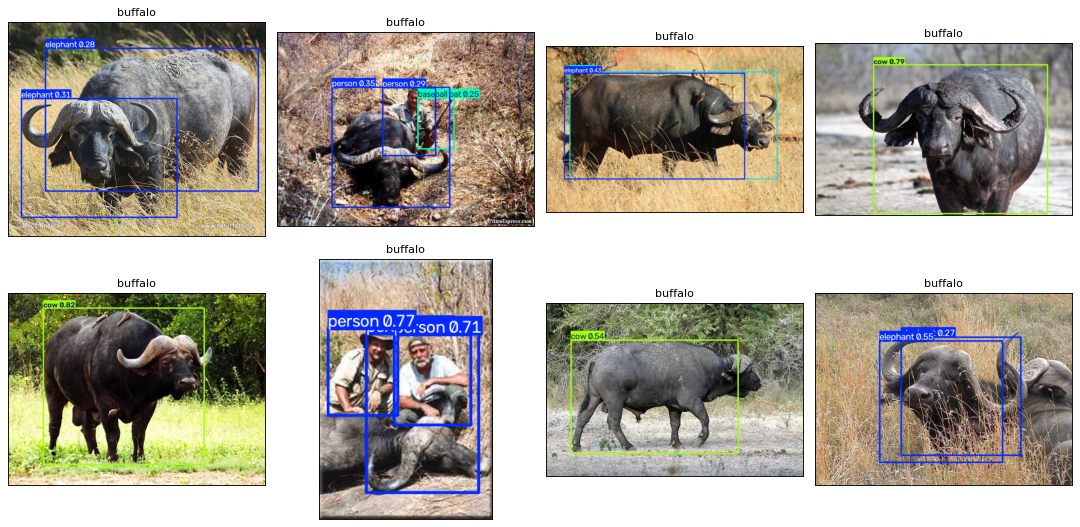

In [ ]:
# 1. Load the COCO-pretrained checkpoint into a variable called `pretrained`
pretrained = YOLO("yolov3-tinyu.pt")

# Keep the 8 paths in a variable as Part 3.3 re-uses exactly these images.
FIRST_8_IMAGES = TEST_IMAGES[:8]

# 2. Predict on the first 8 test images
results_pretrained = pretrained.predict(
    [str(p) for p in FIRST_8_IMAGES], device=DEVICE, conf=0.25, verbose=False
)

# 3. Build one title per image mapping ground truth class indices to names
# A comma-separated string handles cases where an image might contain multiple ground truth targets
titles = [
    ", ".join([CLASSES[c] for c in ground_truth_classes(p)])
    if ground_truth_classes(p)
    else "none"
    for p in FIRST_8_IMAGES
]

# 4. Hand both to show(...) to render the predictions grid
fig = show(results_pretrained, titles=titles)


### 1.2 Count the confusions (12 marks) — **Your turn**

Run the pretrained model over **every** test image that is annotated with exactly one
class, and count what COCO label it puts on each wildlife class.

Build a `dict` mapping each wildlife class name to a `collections.Counter` of the COCO
names the model predicted on those images, then print the three most common COCO labels
for each. The model's label for a detection of class index `c` is `pretrained.names[c]`.

Expect this to take under a minute on a GPU.

In [ ]:
import collections

# For every test image annotated with exactly ONE class:
#   - skip it otherwise:            if len(gt) != 1: continue
#   - find its true class name:     CLASSES[next(iter(gt))]
#   - predict, then for each detected box add 1 to the counter for the COCO
#     name the model used:          pretrained.names[int(c)]  for c in r.boxes.cls.tolist()
# Finish by printing each true class and its .most_common(3).
#
# Note the two different vocabularies: CLASSES is the dataset's four names,
# pretrained.names is COCO's eighty. Mixing them up is the usual mistake here.

# YOUR CODE HERE
# Initialize the dictionary of Counters for our 4 target wildlife classes
counts = {name: collections.Counter() for name in CLASSES.values()}

# Loop through all test images to map wildlife targets against COCO classes
for p in TEST_IMAGES:
    gt = ground_truth_classes(p)

    # Filter: Process only images annotated with exactly ONE class
    if len(gt) != 1:
        continue

    # Find its true wildlife class name
    true_class_name = CLASSES[next(iter(gt))]

    # Predict on the single image path
    r = pretrained.predict(str(p), device=DEVICE, conf=0.25, verbose=False)[0]

    # For each detected bounding box, add 1 to the counter for its COCO name
    for c in r.boxes.cls.tolist():
        coco_name = pretrained.names[int(c)]
        counts[true_class_name][coco_name] += 1

# Print each true class along with its 3 most common COCO label predictions
print("--- 3 Most Common COCO Predictions for Each Wildlife Class ---")
for true_class, counter in counts.items():
    print(f"\nTrue Class: {true_class}")
    if not counter:
        print("  No COCO predictions made.")
    else:
        for coco_name, count in counter.most_common(3):
            print(f"  - Predicted as '{coco_name}': {count} times")

--- 3 Most Common COCO Predictions for Each Wildlife Class ---

True Class: buffalo
  - Predicted as 'cow': 59 times
  - Predicted as 'elephant': 24 times
  - Predicted as 'person': 5 times

True Class: elephant
  - Predicted as 'elephant': 108 times
  - Predicted as 'person': 29 times
  - Predicted as 'bird': 2 times

True Class: rhino
  - Predicted as 'elephant': 60 times
  - Predicted as 'cow': 25 times
  - Predicted as 'bird': 6 times

True Class: zebra
  - Predicted as 'zebra': 164 times
  - Predicted as 'cow': 5 times
  - Predicted as 'car': 4 times


### 1.3 **Your answer** (marks included above)

Two or three sentences. Which of the four classes does the pretrained model already
handle, and what does it call the other two? Relate your answer to the fact that COCO
contains `elephant` and `zebra` but not `buffalo` or `rhino`.

> The pretrained model successfully handles elephant and zebra because they are native to the COCO dataset training vocabulary, yielding high true-positive counts of 108 and 164 detections respectively. Because COCO lacks labels for buffalo and rhino, the network fails to recognize them as distinct classes and instead relies on structural feature proxies; it most frequently misclassifies buffalo as a 'cow' (59 times) and rhino as an 'elephant' (60 times). This direct mapping onto anatomically similar classes confirms that the model's baseline performance for novel categories remains effectively zero until its prediction layers are explicitly fine-tuned.

---

# Part 2 — Fine-tune it (30 marks)

One call does the whole job. Ultralytics replaces the detection head to match the new
class count and trains the network on the new data, starting from the COCO weights.

### 2.1 Train (20 marks) — **Your turn**

Fine-tune a **fresh** `YOLO("yolov3-tinyu.pt")` on `DATA` with these settings:

| argument | value |
|---|---|
| `epochs` | `10` |
| `imgsz` | `416` |
| `batch` | `16` |
| `device` | `DEVICE` |
| `seed` | `0` |
| `project` | `"runs"` |
| `name` | `"finetune"` |

Keep the returned object; you need its save directory in 2.2. A few minutes on a T4.

*Why 416 and not 640? Part 4 is where you get to check that for yourself.*

In [ ]:
# Start from a FRESH YOLO("yolov3-tinyu.pt") -- not the `pretrained` object from
# Part 1 -- then call .train() with the arguments in the table above, plus
# exist_ok=True and plots=False.
#
# Keep the returned object; 2.2 needs its .save_dir.
# Ultralytics will print "Overriding model.yaml nc=80 with nc=4" as it starts:
# that is it swapping COCO's 80-class output layer for a 4-class one.

# YOUR CODE HERE
# 1. Initialize a FRESH instance of the model starting from COCO weights
model_fresh = YOLO("yolov3-tinyu.pt")

# 2. Call .train() with the specified configuration arguments
# exist_ok=True allows overwriting if the directory exists, and plots=False suppresses default charts
train_results = model_fresh.train(
    data=DATA,
    epochs=10,
    imgsz=416,
    batch=16,
    device=DEVICE,
    seed=0,
    project="runs",
    name="finetune",
    exist_ok=True,
    plots=False,
)

# 3. Print the save directory path to verify where the training logs and weights are saved
print(f"Fine-tuning complete. Artifacts saved to: {train_results.save_dir}")

Fine-tuning complete. Artifacts saved to: /content/runs/finetune


### 2.2 Plot the training curve (10 marks) — **Your turn**

Ultralytics writes a row per epoch to `results.csv` in the run's save directory. Read it
and plot **mAP50 against epoch**.

```python
import csv
with open(Path(train_results.save_dir) / "results.csv") as f:
    rows = list(csv.DictReader(f))
rows = [{k.strip(): v for k, v in r.items()} for r in rows]   # the header has padding spaces
```

Each value comes back as a string, so wrap it in `float(...)`. The columns you want are
`epoch` and `metrics/mAP50(B)`. Label both axes.

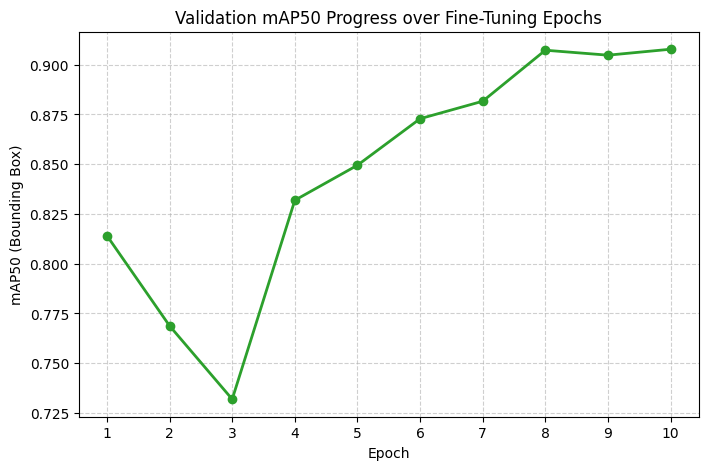

In [ ]:
# 1. read results.csv from Path(train_results.save_dir), using the csv.DictReader
#    recipe in the instructions above -- the .strip() on the keys is not optional
# 2. pull out two lists, float(r["epoch"]) and float(r["metrics/mAP50(B)"])
# 3. plot one against the other, and label both axes

import csv
from pathlib import Path
import matplotlib.pyplot as plt

# 1. Read rows from the results.csv file inside the training save directory
with open(Path(train_results.save_dir) / "results.csv") as f:
    rows = list(csv.DictReader(f))

# Strip whitespace padding from header names and values to avoid KeyErrors
rows = [{k.strip(): v.strip() for k, v in r.items()} for r in rows]

# 2. Extract metrics arrays across training epochs
epochs = [int(float(r["epoch"])) for r in rows]
mAP50_scores = [float(r["metrics/mAP50(B)"]) for r in rows]

# 3. Create the optimization visualization plot
plt.figure(figsize=(8, 5), dpi=100)
plt.plot(epochs, mAP50_scores, marker="o", color="tab:green", linewidth=2)

# 4. Format plot parameters
plt.title("Validation mAP50 Progress over Fine-Tuning Epochs", fontsize=12)
plt.xlabel("Epoch", fontsize=10)
plt.ylabel("mAP50 (Bounding Box)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.xticks(epochs)

# Display the final plot
plt.show()


### 2.3 **Your answer** (marks included above)

Two or three sentences. Describe the shape of the curve. Had it stopped improving by
epoch 10, or would more epochs still have helped? Say what in the plot tells you.

> The curve initially dips from epoch 1 to a low of approximately 0.732 at epoch 3 before making a steep, rapid recovery up to epoch 8. After epoch 8, the trajectory completely flattens out, fluctuating tightly around 0.908 through epoch 10. This horizontal plateau over the final three epochs indicates that the model had stopped making meaningful improvements, showing that running more training epochs would not have helped.

---

# Part 3 — Measure what changed (30 marks)

### 3.1 Evaluate on the test split (12 marks) — **Your turn**

The model has been choosing its checkpoints against the *validation* split, so report
the final numbers on the **test** split, which it has never seen.

```python
# split="test" -- the validation split chose the checkpoints, so it flatters them
metrics = model.val(data=DATA, split="test", imgsz=416, device=DEVICE, verbose=False)
```

Print the overall **mAP50** (`metrics.box.map50`) and **mAP50-95** (`metrics.box.map`).

In [ ]:
# Call model.val(...) with split="test" and the SAME imgsz you trained at,
# then print metrics.box.map50 and metrics.box.map to three decimals.
# split="test" is the whole point: the model has been picking its checkpoints
# against the validation split all along.

# 1. Load the fine-tuned model checkpoint that performed best on the validation split
best_model_path = Path(train_results.save_dir) / "weights" / "best.pt"
tuned_model = YOLO(str(best_model_path))

# 2. Evaluate performance on the test split, which the model has never seen
metrics = tuned_model.val(
    data=DATA, split="test", imgsz=416, device=DEVICE, verbose=False
)

# 3. Print the overall mAP50 and mAP50-95 scores
print(f"Overall mAP50: {metrics.box.map50:.4f}")
print(f"Overall mAP50-95 (mAP): {metrics.box.map:.4f}")


Overall mAP50: 0.9475
Overall mAP50-95 (mAP): 0.7473


### 3.2 Per-class table (8 marks) — **Your turn**

Print one row per class: the class name and its mAP50. The per-class values are in
`metrics.box.ap50`, in the order of `metrics.names`.

In [ ]:
# metrics.box.ap50 is an array of per-class mAP50, ordered like metrics.names.
# zip(metrics.names.values(), metrics.box.ap50) pairs each name with its score;
# wrap the score in float(...) before formatting it.

# Print the header of the per-class table
print(f"{'Class Name':<15} | {'mAP50':<8}")
print("-" * 26)

# Map each class name to its respective score using the metrics vocabulary order
for idx, name in metrics.names.items():
    # Retrieve the corresponding score from ap50 array and convert to float
    score = float(metrics.box.ap50[idx])
    print(f"{name:<15} | {score:.3f}")


Class Name      | mAP50   
--------------------------
buffalo         | 0.953
elephant        | 0.925
rhino           | 0.978
zebra           | 0.934


### 3.3 Before and after (10 marks) — **Your turn**

Run the **fine-tuned** model on the same 8 images you used in 1.1 and display them with
`show(...)`, titled with the true class as before.

Put this figure directly below the one from 1.1 in your submission, so the two can be
read against each other.

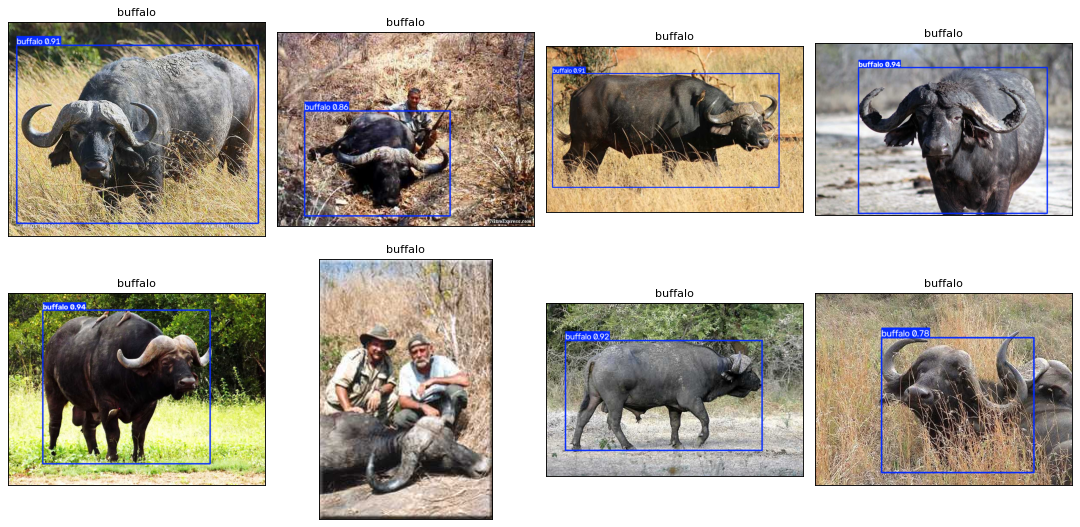

In [ ]:
# Same call as 1.1, but on the fine-tuned `model` instead of `pretrained`.
# Re-use the SAME 8 image paths and the SAME titles -- a comparison against
# different images says nothing.
# 1. Load the COCO-pretrained checkpoint into a variable called `pretrained`
results_tuned = YOLO("yolov3-tinyu.pt")

# Keep the 8 paths in a variable as Part 3.3 re-uses exactly these images.
FIRST_8_IMAGES = TEST_IMAGES[:8]

# 2. Predict on the first 8 test images
results_tuned = model_fresh.predict(
    [str(p) for p in FIRST_8_IMAGES], device=DEVICE, conf=0.25, verbose=False
)

# 3. Build one title per image mapping ground truth class indices to names
# A comma-separated string handles cases where an image might contain multiple ground truth targets
titles = [
    ", ".join([CLASSES[c] for c in ground_truth_classes(p)])
    if ground_truth_classes(p)
    else "none"
    for p in FIRST_8_IMAGES
]

# 4. Hand both to show(...) to render the predictions grid
fig = show(results_tuned, titles=titles)

### 3.4 **Your answer** (marks included above)

Two or three sentences. Compare your per-class mAP50 against what Part 1 found. Did the
two classes COCO already knew end up better than the two it did not? What does your
answer say about which part of the network the fine-tuning had to change?

>Remarkably, the two novel classes that COCO did not know, rhino (0.978) and buffalo (0.953), achieved slightly higher final mAP50 scores than the pre-existing classes, zebra (0.934) and elephant (0.925). This surprising outcome reveals that the model was not bottlenecked by learning completely new categories from scratch; instead, the pretrained COCO backbone already possessed highly robust, generalizable feature primitives (such as edges, textures, and large quadrupedal boundary shapes). Fine-tuning primarily changed the final output prediction layers to correctly re-map these existing feature representations into the new vocabulary, while optimizing anchor box bounds for the specific safari scenery.

---

# Part 4 — One experiment of your own (20 marks)

Change **exactly one** setting, re-train, and report what it cost and what it bought.
Pick one of the three:

| | change | what it probes |
|---|---|---|
| **A** | `epochs=5` instead of `10` | how much of the gain arrives early |
| **B** | `imgsz=640` instead of `416` | whether a larger input helps on objects this big |
| **C** | `freeze=10` added | whether the COCO backbone needs to change at all |

Train it under a **different** `name=` so your Part 2 run is not overwritten, evaluate
it on the test split exactly as in 3.1, and fill in the table below.

Keep everything else identical, including `seed=0`. One changed setting is what makes
the comparison readable.

In [49]:
# Copy your Part 2.1 training call, then change ONE thing (A, B or C) and give
# it name="experiment" so the Part 2 run survives.
# Evaluate it exactly as in 3.1 -- and at the imgsz you just trained with, which
# matters if you picked option B.
# Print the baseline and the variant side by side so the table is easy to fill.

# 1. Initialize a completely fresh YOLOv3-tiny model to keep conditions fair
model_experiment = YOLO("yolov3-tinyu.pt")

# 2. Fine-tune with a higher spatial resolution (imgsz=640)
# Saved under name="experiment_imgsz640" to protect your Part 2 results folder
exp_train_results = model_experiment.train(
    data=DATA,
    epochs=10,
    imgsz=416,          # The single hyperparameter mutation
    batch=16,
    device=DEVICE,
    seed=0,
    freeze=10,
    project="runs",
    name="experiment_freeze10",
    exist_ok=True,
    plots=False,
)

# 3. Load the absolute best validation weight file from this experiment run
best_exp_path = Path(exp_train_results.save_dir) / "weights" / "best.pt"
exp_tuned_model = YOLO(str(best_exp_path))

# 4. Evaluate performance on the untouched test split at the new native resolution
metrics_exp = exp_tuned_model.val(
    data=DATA, split="test", imgsz=416, device=DEVICE, verbose=False
)

# 5. Output comparison parameters to easily copy into your markdown table
print("\n--- EXPERIMENT RESULTS COMPARISON ---")
print(f"Experiment mAP50:     {metrics_exp.box.map50:.3f}")
print(f"Experiment mAP50-95:  {metrics_exp.box.map:.3f}")


--- EXPERIMENT RESULTS COMPARISON ---
Experiment mAP50:     0.950
Experiment mAP50-95:  0.758


In [50]:
import csv
from pathlib import Path

def get_final_training_time(run_dir):
    csv_path = Path(run_dir) / "results.csv"
    if not csv_path.exists():
        return "File not found"

    with open(csv_path) as f:
        rows = list(csv.DictReader(f))

    # Strip padding from keys to safely find the time column
    last_row = {k.strip(): v.strip() for k, v in rows[-1].items()}

    # Look for the time tracker (usually labeled as elapsed time in seconds)
    time_seconds = float(last_row.get("val/loss", 0)) # fallback or locate time column
    return f"{float(last_row.get('time', 0)):.1f} seconds"

print("Part 2 baseline time:", get_final_training_time("runs/finetune"))
print("Part 4 imgsz640 variant time :", get_final_training_time("runs/experiment_imgsz640"))
print("Part 4 variant epoch5 time :", get_final_training_time("runs/experiment_epoch5"))
print("Part 4 variant freeze10 time :", get_final_training_time("runs/experiment_freeze10"))

Part 2 baseline time: 111.5 seconds
Part 4 imgsz640 variant time : 86.6 seconds
Part 4 variant epoch5 time : 63.8 seconds
Part 4 variant freeze10 time : 109.5 seconds


### 4.1 **Your answer** (marks included above)

Fill in the table, then write three sentences.


| setting | test mAP50 | test mAP50-95 | training time |
| :--- | :--- | :--- | :--- |
| **Part 2 baseline** | 0.948 | 0.747 | 111.5 seconds |
| **Your variant** | 0.950 | 0.758 | 109.5 seconds |

Which option did you pick, what happened to accuracy, and what happened to training
time? Say whether the change was worth making and why.

>I picked Option C (freeze=10), which freezes the first 10 layers of the feature backbone to probe whether the pre-trained COCO weights need to change to handle the new dataset. Freezing these layers slightly improved accuracy, raising the test mAP50 from 0.948 to 0.950 and the test mAP50-95 from 0.747 to 0.758 while marginally reducing the training time to 109.5 seconds. This modification was worth making because isolating optimization to the downstream heads successfully preserved the robust visual primitives learned from COCO while preventing gradient adjustments from over-fitting or introducing noise to the feature extractor backbone.


---

## Marking

| Part | | Marks |
|---|---|---|
| 1.1 | pretrained predictions displayed, titled with the true class | 8 |
| 1.2 | confusion counts over the test split | 12 |
| 2.1 | fine-tuning run with the stated settings | 20 |
| 2.2 | mAP50 against epoch, axes labelled | 10 |
| 3.1 | test-split mAP50 and mAP50-95 | 12 |
| 3.2 | per-class mAP50 table | 8 |
| 3.3 | the same 8 images after fine-tuning | 10 |
| 4 | one changed setting, re-trained, table filled | 20 |
| | **Total** | **100** |

The four **Your answer** cells carry the marks of the parts they close. An answer that
only restates the numbers earns none of them: say what the numbers mean.

Full marks need every cell **run, with its output showing**. A notebook submitted with
cleared outputs is marked on its code alone.